# Practice 1 – FashionMNIST: Data Pipeline & Phân tích dữ liệu

| Giai đoạn | Nội dung |
|---|---|
| **1. Data Collection** | Xác định bài toán → xác định dữ liệu cần → thu thập |
| **2. Data Preprocessing** | Kiểm tra định dạng, làm sạch, lấy mẫu / chia tập |
| **3. Data Transformation** | Chuẩn hóa (normalize), giảm chiều (PCA), đóng gói DataLoader |


## 0. Chuẩn bị môi trường

In [1]:
import random, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.14.1+cpu | Device: cpu


## 1. Data Collection

**Xác định bài toán:** phân loại ảnh (multi-class classification, 10 lớp) các món đồ thời trang.

**Dữ liệu cần:** ảnh đầu vào + nhãn lớp tương ứng (học có giám sát).

**Nguồn dữ liệu:** bộ **Fashion-MNIST** do Zalando Research công bố (cũng có trên Kaggle và GitHub `zalandoresearch/fashion-mnist`). Ở đây tải trực tiếp qua `torchvision.datasets.FashionMNIST` (tự động tải lần đầu, các lần sau dùng lại bản đã lưu trong `./data`).

Lúc này **chưa** truyền `transform`, để quan sát dữ liệu thô trước.

In [2]:
DATA_DIR = "./data"
raw_train = datasets.FashionMNIST(root=DATA_DIR, train=True,  download=True)
raw_test  = datasets.FashionMNIST(root=DATA_DIR, train=False, download=True)

CLASS_NAMES = raw_train.classes
print(CLASS_NAMES)

100.0%
100.0%
100.0%
100.0%

['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']


### 1.1 Tổng quan dữ liệu thô

In [3]:
X_train_raw = raw_train.data.numpy()      # (N, 28, 28), uint8
y_train     = raw_train.targets.numpy()
X_test_raw  = raw_test.data.numpy()
y_test      = raw_test.targets.numpy()

overview = pd.DataFrame({
    "tập":        ["train", "test"],
    "số mẫu":     [len(X_train_raw), len(X_test_raw)],
    "shape ảnh":  [X_train_raw.shape[1:], X_test_raw.shape[1:]],
    "dtype":      [X_train_raw.dtype, X_test_raw.dtype],
    "pixel min":  [X_train_raw.min(), X_test_raw.min()],
    "pixel max":  [X_train_raw.max(), X_test_raw.max()],
    "số lớp":     [len(np.unique(y_train)), len(np.unique(y_test))],
})
overview

,tập,số mẫu,shape ảnh,dtype,pixel min,pixel max,số lớp
0,train,60000,"(28, 28)",uint8,0,255,10
1,test,10000,"(28, 28)",uint8,0,255,10


## 2. Data Preprocessing

### 2.1 Làm sạch (Cleaning)
Kiểm tra: nhãn hợp lệ, ảnh trống, ảnh trùng lặp trong train, và **rò rỉ dữ liệu** (ảnh train xuất hiện lại trong test).
(Dữ liệu ảnh `uint8` nên không thể có giá trị NaN; chỉ cần kiểm tra khoảng giá trị 0–255 ở bảng trên.)

In [4]:
# Nhãn hợp lệ
assert set(np.unique(y_train)) == set(range(10)), "Nhãn train bất thường"
assert set(np.unique(y_test))  == set(range(10)), "Nhãn test bất thường"

# Ảnh trống (toàn pixel 0)
blank_train = int((X_train_raw.reshape(len(X_train_raw), -1).max(axis=1) == 0).sum())

# Ảnh trùng lặp + rò rỉ train/test
def img_hashes(X):
    return [hashlib.md5(x.tobytes()).hexdigest() for x in X]

h_train, h_test = img_hashes(X_train_raw), img_hashes(X_test_raw)
dup_train = len(h_train) - len(set(h_train))
leak      = len(set(h_train) & set(h_test))

print(f"Ảnh trống trong train        : {blank_train}")
print(f"Ảnh trùng lặp trong train    : {dup_train}")
print(f"Ảnh train xuất hiện ở test   : {leak}")

Ảnh trống trong train        : 0
Ảnh trùng lặp trong train    : 0
Ảnh train xuất hiện ở test   : 0


### 2.2 Phân bố lớp (Class distribution)
Dữ liệu có cân bằng không? Điều này quyết định có thể dùng **accuracy** hay cần thêm precision/recall/F1 (xem slide 14).

,label,class,train,test,train_%
0,0,T-shirt/top,6000,1000,10.0
1,1,Trouser,6000,1000,10.0
2,2,Pullover,6000,1000,10.0
3,3,Dress,6000,1000,10.0
4,4,Coat,6000,1000,10.0
5,5,Sandal,6000,1000,10.0
6,6,Shirt,6000,1000,10.0
7,7,Sneaker,6000,1000,10.0
8,8,Bag,6000,1000,10.0
9,9,Ankle boot,6000,1000,10.0


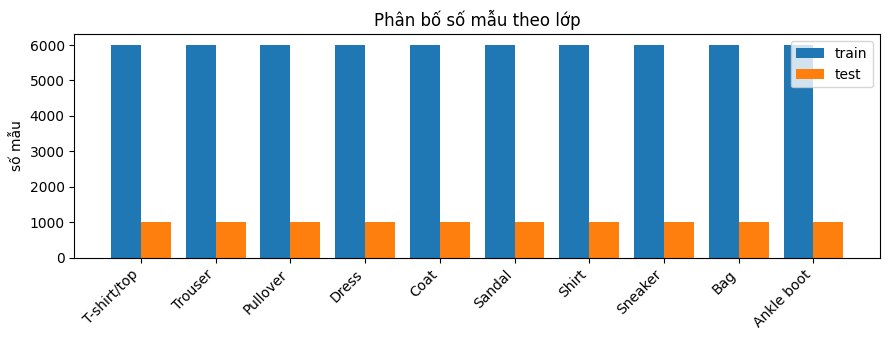

In [5]:
df_dist = pd.DataFrame({
    "label": range(10),
    "class": CLASS_NAMES,
    "train": np.bincount(y_train, minlength=10),
    "test":  np.bincount(y_test,  minlength=10),
})
df_dist["train_%"] = (df_dist["train"] / len(y_train) * 100).round(2)
display(df_dist)

fig, ax = plt.subplots(figsize=(9, 3.5))
x = np.arange(10); w = 0.4
ax.bar(x - w/2, df_dist["train"], w, label="train")
ax.bar(x + w/2, df_dist["test"],  w, label="test")
ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_ylabel("số mẫu"); ax.set_title("Phân bố số mẫu theo lớp"); ax.legend()
plt.tight_layout(); plt.show()

### 2.3 Quan sát trực quan mẫu dữ liệu

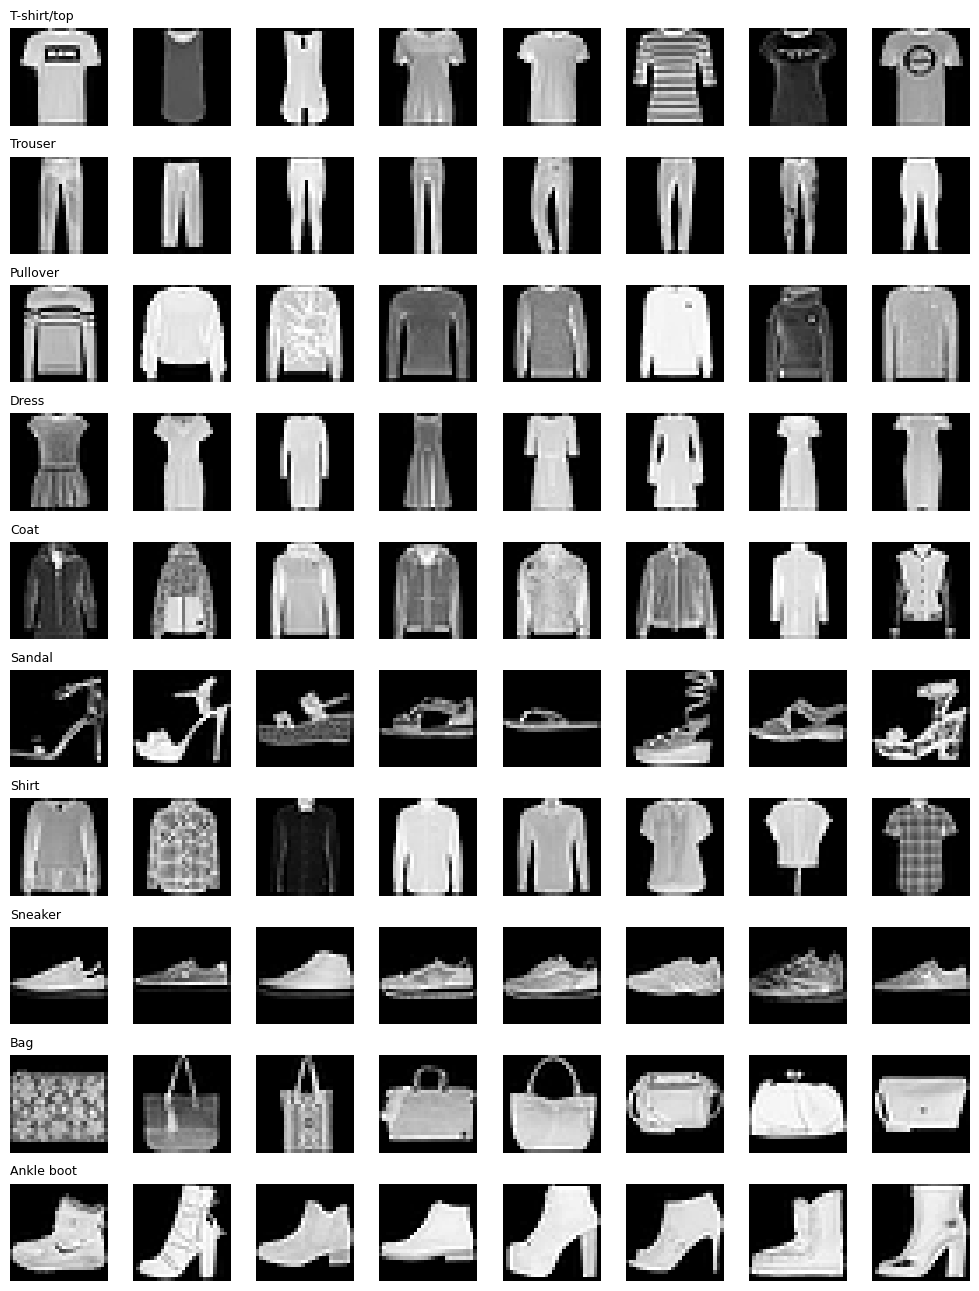

In [6]:
fig, axes = plt.subplots(10, 8, figsize=(10, 13))
for c in range(10):
    idx = np.where(y_train == c)[0][:8]
    for j, i in enumerate(idx):
        ax = axes[c, j]
        ax.imshow(X_train_raw[i], cmap="gray")
        ax.axis("off")
        if j == 0:
            ax.set_title(CLASS_NAMES[c], fontsize=9, loc="left")
plt.tight_layout(); plt.show()

### 2.4 Ảnh trung bình của từng lớp

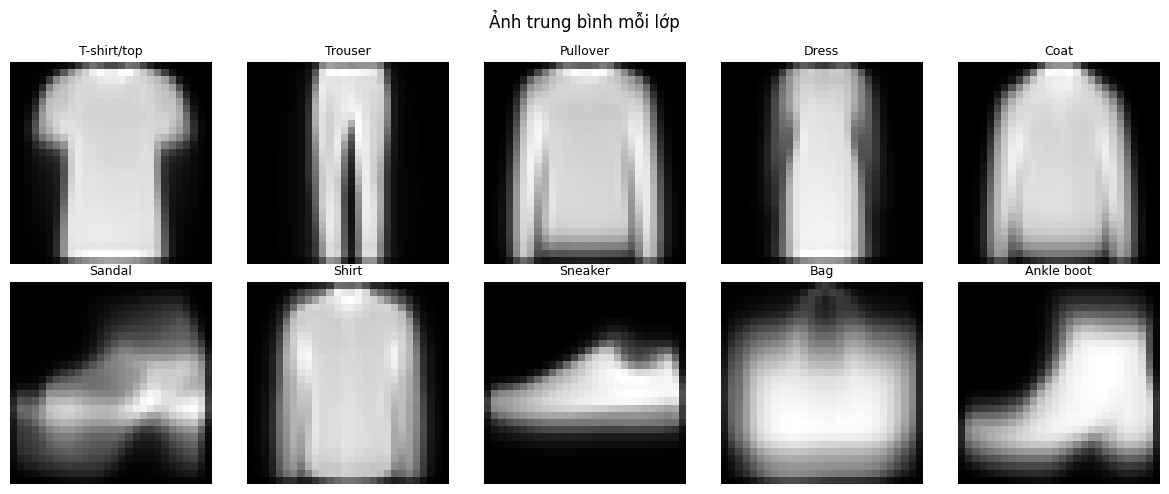

In [7]:
Xf = X_train_raw.astype(np.float32) / 255.0
class_means = np.stack([Xf[y_train == c].mean(axis=0) for c in range(10)])

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for c, ax in enumerate(axes.ravel()):
    ax.imshow(class_means[c], cmap="gray"); ax.set_title(CLASS_NAMES[c], fontsize=9); ax.axis("off")
plt.suptitle("Ảnh trung bình mỗi lớp"); plt.tight_layout(); plt.show()

### 2.5 Thống kê cường độ pixel

Mean toàn bộ (0-1): 0.2860
Std  toàn bộ (0-1): 0.3530
Tỉ lệ pixel = 0   : 50.21%


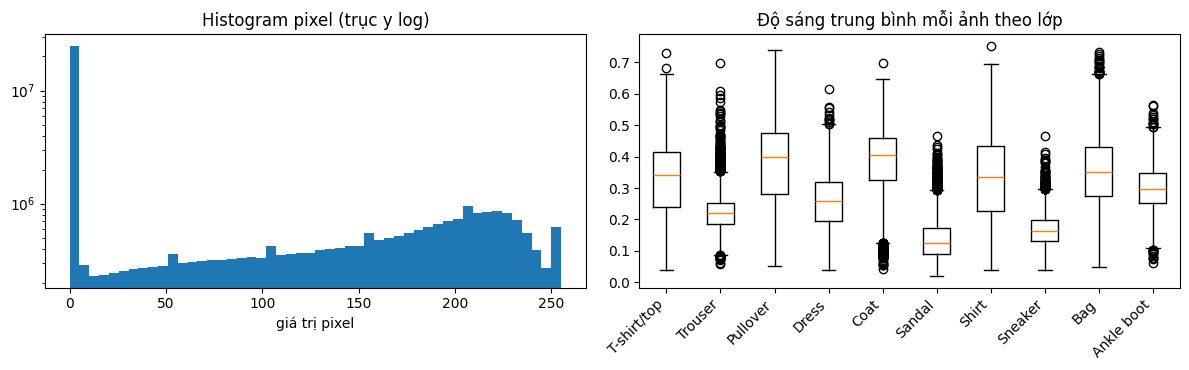

In [8]:
print(f"Mean toàn bộ (0-1): {Xf.mean():.4f}")
print(f"Std  toàn bộ (0-1): {Xf.std():.4f}")
print(f"Tỉ lệ pixel = 0   : {(X_train_raw == 0).mean()*100:.2f}%")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

axes[0].hist(X_train_raw.ravel(), bins=50, log=True)
axes[0].set_title("Histogram pixel (trục y log)"); axes[0].set_xlabel("giá trị pixel")

brightness = Xf.mean(axis=(1, 2))   # độ sáng trung bình từng ảnh
axes[1].boxplot([brightness[y_train == c] for c in range(10)])
axes[1].set_xticks(range(1, 11)); axes[1].set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
axes[1].set_title("Độ sáng trung bình mỗi ảnh theo lớp")

plt.tight_layout(); plt.show()

### 2.6 Mức độ giống nhau giữa các lớp
Khoảng cách Euclid giữa các ảnh trung bình: cặp lớp nào **gần nhau** thì mô hình dễ nhầm lẫn. Có thể dùng để giải thích confusion matrix ở bước đánh giá.

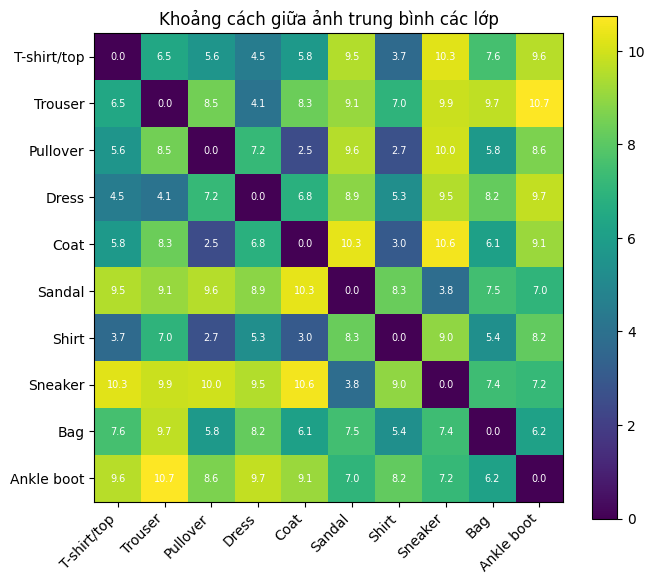

5 cặp lớp giống nhau nhất:
  Pullover     - Coat        : 2.48
  Pullover     - Shirt       : 2.68
  Coat         - Shirt       : 3.02
  T-shirt/top  - Shirt       : 3.72
  Sandal       - Sneaker     : 3.84


In [9]:
flat = class_means.reshape(10, -1)
dist = np.linalg.norm(flat[:, None, :] - flat[None, :, :], axis=2)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(dist, cmap="viridis")
ax.set_xticks(range(10)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(CLASS_NAMES)
for i in range(10):
    for j in range(10):
        ax.text(j, i, f"{dist[i, j]:.1f}", ha="center", va="center", color="w", fontsize=7)
plt.colorbar(im); ax.set_title("Khoảng cách giữa ảnh trung bình các lớp")
plt.tight_layout(); plt.show()

pairs = sorted((dist[i, j], CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(10) for j in range(i + 1, 10))
print("5 cặp lớp giống nhau nhất:")
for d, a, b in pairs[:5]:
    print(f"  {a:12s} - {b:12s}: {d:.2f}")

## 3. Data Transformation

### 3.1 Giảm chiều bằng PCA (Decomposition)
Mỗi ảnh có 784 chiều. PCA giúp xem cấu trúc dữ liệu: cần bao nhiêu thành phần để giữ phần lớn thông tin, và các lớp có tách nhau trong không gian 2D không. (Chỉ để phân tích, **không** dùng PCA làm đầu vào cho mạng.)

50 thành phần giữ 86.3% phương sai


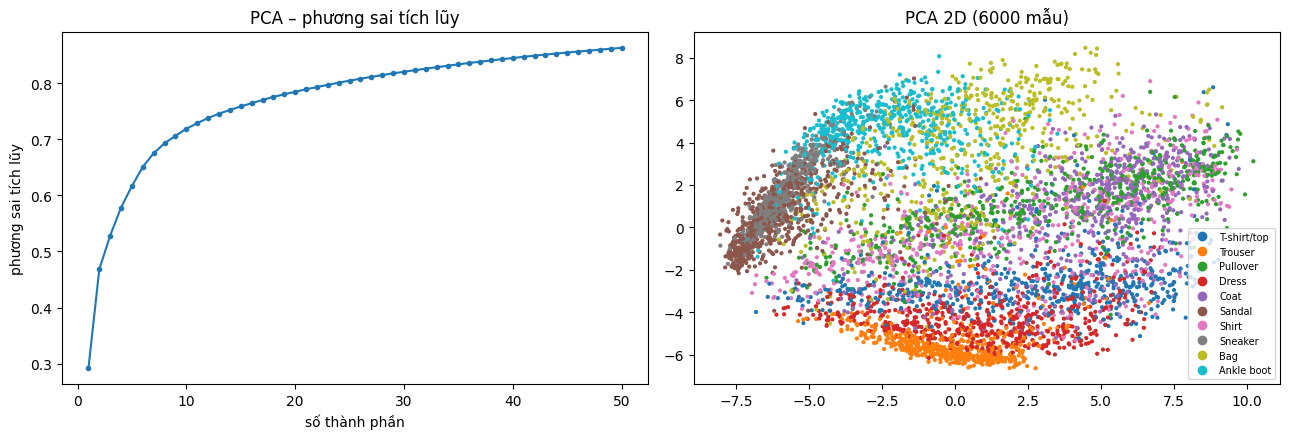

In [10]:
from sklearn.decomposition import PCA

rng = np.random.default_rng(SEED)
sub = rng.choice(len(Xf), size=6000, replace=False)
X_sub = Xf[sub].reshape(len(sub), -1)
y_sub = y_train[sub]

pca = PCA(n_components=50, random_state=SEED).fit(X_sub)
cum = np.cumsum(pca.explained_variance_ratio_)
print(f"Số thành phần để giữ 90% phương sai: {np.argmax(cum >= 0.90) + 1}" if cum[-1] >= 0.90
      else f"50 thành phần giữ {cum[-1]*100:.1f}% phương sai")

Z = pca.transform(X_sub)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(range(1, 51), cum, marker="o", ms=3)
axes[0].set_xlabel("số thành phần"); axes[0].set_ylabel("phương sai tích lũy"); axes[0].set_title("PCA – phương sai tích lũy")
sc = axes[1].scatter(Z[:, 0], Z[:, 1], c=y_sub, cmap="tab10", s=4)
axes[1].legend(sc.legend_elements()[0], CLASS_NAMES, fontsize=7, loc="best")
axes[1].set_title("PCA 2D (6000 mẫu)")
plt.tight_layout(); plt.show()

### 3.2 Chia tập Train / Validation / Test
- **Train:** 54.000 ảnh (học).
- **Validation:** 6.000 ảnh (chọn hyperparameter, phát hiện overfitting).
- **Test:** 10.000 ảnh gốc (đánh giá cuối cùng, **không đụng tới** khi tuning).

In [11]:
N_VAL = 6000
g = torch.Generator().manual_seed(SEED)
perm = torch.randperm(len(raw_train), generator=g)
val_idx, train_idx = perm[:N_VAL].tolist(), perm[N_VAL:].tolist()

split_df = pd.DataFrame({
    "class": CLASS_NAMES,
    "train": np.bincount(y_train[train_idx], minlength=10),
    "val":   np.bincount(y_train[val_idx],   minlength=10),
})
print(f"train={len(train_idx)}, val={len(val_idx)}, test={len(raw_test)}")
split_df

train=54000, val=6000, test=10000


,class,train,val
0,T-shirt/top,5400,600
1,Trouser,5413,587
2,Pullover,5353,647
3,Dress,5445,555
4,Coat,5390,610
5,Sandal,5368,632
6,Shirt,5390,610
7,Sneaker,5406,594
8,Bag,5423,577
9,Ankle boot,5412,588


### 3.3 Chuẩn hóa (Normalization)
Tính `mean` và `std` **chỉ trên tập train** (tránh rò rỉ thông tin từ val/test), rồi áp dụng cho cả ba tập:

$$x' = \frac{x - \mu}{\sigma}$$

In [12]:
train_pixels = torch.from_numpy(Xf[train_idx])
MEAN, STD = train_pixels.mean().item(), train_pixels.std().item()
print(f"MEAN = {MEAN:.4f} | STD = {STD:.4f}")

transform = transforms.Compose([
    transforms.ToTensor(),                  # uint8 [0,255] -> float [0,1], shape (1,28,28)
    transforms.Normalize((MEAN,), (STD,)),  # -> mean ~ 0, std ~ 1
])

full_train = datasets.FashionMNIST(DATA_DIR, train=True,  download=False, transform=transform)
test_ds    = datasets.FashionMNIST(DATA_DIR, train=False, download=False, transform=transform)
train_ds, val_ds = Subset(full_train, train_idx), Subset(full_train, val_idx)

MEAN = 0.2858 | STD = 0.3529


### 3.4 Đóng gói DataLoader

In [13]:
BATCH_SIZE = 128
pin = device.type == "cuda"

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0, pin_memory=pin)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=pin)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=pin)

images, labels = next(iter(train_loader))
print("Batch ảnh :", images.shape, images.dtype)
print("Batch nhãn:", labels.shape, labels.dtype)
print(f"Sau chuẩn hóa: mean={images.mean():.3f}, std={images.std():.3f}, min={images.min():.2f}, max={images.max():.2f}")

Batch ảnh : torch.Size([128, 1, 28, 28]) torch.float32
Batch nhãn: torch.Size([128]) torch.int64
Sau chuẩn hóa: mean=0.071, std=1.031, min=-0.81, max=2.02


### 3.5 Kiểm tra lại sau biến đổi (trước vs sau chuẩn hóa)

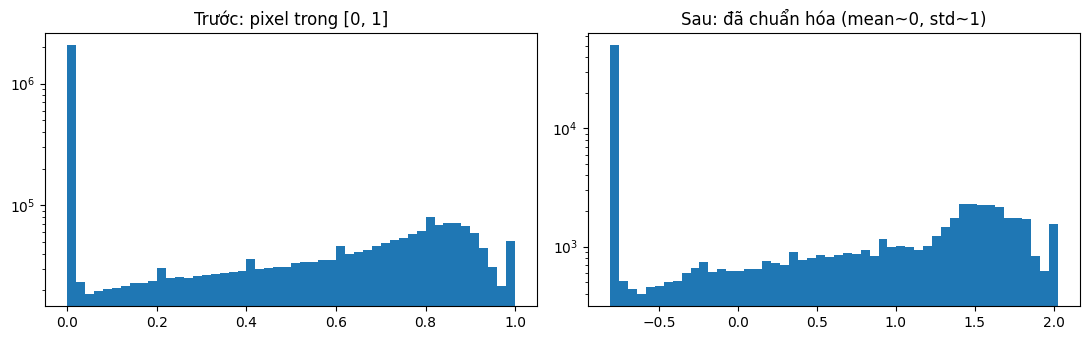

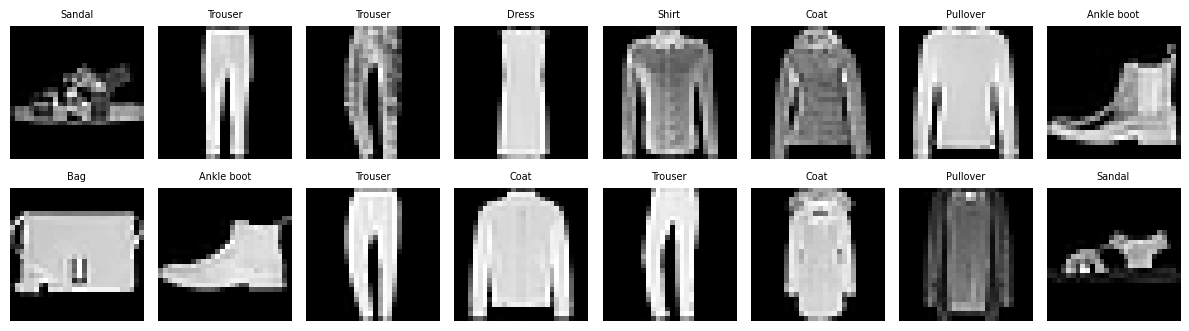

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(Xf[train_idx[:5000]].ravel(), bins=50, log=True); axes[0].set_title("Trước: pixel trong [0, 1]")
axes[1].hist(images.numpy().ravel(), bins=50, log=True);        axes[1].set_title("Sau: đã chuẩn hóa (mean~0, std~1)")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, img, lab in zip(axes.ravel(), images[:16], labels[:16]):
    ax.imshow(img.squeeze(), cmap="gray"); ax.set_title(CLASS_NAMES[lab], fontsize=7); ax.axis("off")
plt.tight_layout(); plt.show()

## 4. Tổng kết Data Pipeline

| Bước | Việc đã làm | Kết quả |
|---|---|---|
| Collection | Tải FashionMNIST qua torchvision | 60.000 train + 10.000 test, ảnh xám 28×28, 10 lớp |
| Cleaning | Kiểm tra nhãn, ảnh trống, trùng lặp, rò rỉ | xem số liệu mục 2.1 |
| EDA | Phân bố lớp, ảnh mẫu, ảnh trung bình, histogram pixel, độ giống giữa các lớp | xem mục 2.2 – 2.6 |
| Decomposition | PCA | số thành phần cần thiết, mức độ tách lớp |
| Sampling | Chia 54.000 / 6.000 / 10.000 | train / val / test |
| Normalization | z-score với mean, std của tập train | mean≈0, std≈1 |
| Loading | DataLoader batch 128 | sẵn sàng cho training loop |

### Gợi ý ý để viết nhận xét trong báo cáo
- Dữ liệu **cân bằng** hay không (số mẫu mỗi lớp ở mục 2.2) → vì vậy dùng accuracy có hợp lý không.
- Những lớp **dễ nhầm** (cặp gần nhau ở mục 2.6, thường là nhóm áo: T-shirt, Shirt, Pullover, Coat) → đối chiếu với confusion matrix sau khi train.
- Số thành phần PCA cần để giữ 90% phương sai cho thấy dữ liệu **dư thừa** nhiều (784 chiều nhưng thông tin nằm trong không gian thấp hơn nhiều).
- Giải thích vì sao chuẩn hóa chỉ dùng thống kê của tập train (tránh data leakage).
- Nên đối chiếu `MEAN`, `STD` bạn tính được với giá trị thường gặp của FashionMNIST (khoảng 0.286 và 0.353).

---
# PHẦN 2 – XÂY DỰNG VÀ HUẤN LUYỆN MÔ HÌNH

Quy trình (Chương 2 slide 18 và Chương 3 slide 3):
**Data → Model → Loss + Optimizer → Training loop → Validation → Đánh giá trên test → Lưu / nạp model**

## 5. Xây dựng mô hình (MLP)

MLP = các lớp Fully Connected xếp chồng. Ảnh 28×28 được **flatten** thành vector 784 chiều (slide 16 Chương 2: cách này mất thông tin không gian, phần bonus bên dưới sẽ so sánh với CNN).

In [15]:
import time, copy
import torch.nn as nn
from torch.utils.data import TensorDataset
from sklearn.metrics import classification_report, confusion_matrix

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

### 5.1 Tăng tốc nạp dữ liệu
Pipeline torchvision ở Phần 1 áp `ToTensor` + `Normalize` **từng ảnh, mỗi epoch** nên khá chậm khi phải chạy nhiều thí nghiệm. Vì phép biến đổi là cố định, ta tính trước **một lần** thành tensor (cùng `MEAN`, `STD` của tập train) rồi đưa vào `TensorDataset` + `DataLoader`. Kết quả toán học giống hệt, được kiểm tra ngay bên dưới.

In [16]:
X_train_t = ((torch.from_numpy(Xf[train_idx]) - MEAN) / STD).unsqueeze(1)
y_train_t = torch.from_numpy(y_train[train_idx]).long()
X_val_t   = ((torch.from_numpy(Xf[val_idx]) - MEAN) / STD).unsqueeze(1)
y_val_t   = torch.from_numpy(y_train[val_idx]).long()
X_test_t  = ((torch.from_numpy(X_test_raw.astype(np.float32) / 255.0) - MEAN) / STD).unsqueeze(1)
y_test_t  = torch.from_numpy(y_test).long()

# Kiểm tra: khớp với pipeline torchvision ở Phần 1
x0, y0 = train_ds[0]
print("Khớp pipeline torchvision:", torch.allclose(x0, X_train_t[0], atol=1e-5), int(y0) == int(y_train_t[0]))
print("Train:", tuple(X_train_t.shape), "| Val:", tuple(X_val_t.shape), "| Test:", tuple(X_test_t.shape))

def make_loaders(batch_size=128):
    pin = device.type == "cuda"
    tr = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=batch_size, shuffle=True,  num_workers=0, pin_memory=pin)
    va = DataLoader(TensorDataset(X_val_t,   y_val_t),   batch_size=512,        shuffle=False, num_workers=0, pin_memory=pin)
    te = DataLoader(TensorDataset(X_test_t,  y_test_t),  batch_size=512,        shuffle=False, num_workers=0, pin_memory=pin)
    return tr, va, te

Khớp pipeline torchvision: True True
Train: (54000, 1, 28, 28) | Val: (6000, 1, 28, 28) | Test: (10000, 1, 28, 28)


### 5.2 Định nghĩa kiến trúc

In [17]:
class MLP(nn.Module):
    def __init__(self, in_dim=784, hidden_sizes=(256, 128), num_classes=10, dropout=0.2):
        super().__init__()
        layers = [nn.Flatten()]
        prev = in_dim
        for h in hidden_sizes:
            layers += [nn.Linear(prev, h), nn.ReLU(), nn.Dropout(dropout)]
            prev = h
        layers.append(nn.Linear(prev, num_classes))   # lớp ra: logits (CrossEntropyLoss đã gồm softmax)
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)

def count_params(model):
    return sum(p.numel() for p in model.parameters())

model = MLP().to(device)
print(model)
print("Số tham số:", f"{count_params(model):,}")

# Kiểm tra shape: batch (128,1,28,28) -> logits (128,10)
with torch.no_grad():
    print("Output shape:", model(images.to(device)).shape)

MLP(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=256, out_features=128, bias=True)
    (5): ReLU()
    (6): Dropout(p=0.2, inplace=False)
    (7): Linear(in_features=128, out_features=10, bias=True)
  )
)
Số tham số: 235,146
Output shape: torch.Size([128, 10])


## 6. Huấn luyện (Training loop + Validation)

Mỗi batch trong training làm đúng 6 bước ở slide 8–9 Chương 3: `zero_grad` → forward → tính loss → `backward` → `optimizer.step()`.
Sau mỗi epoch đánh giá trên **validation** (`model.eval()` + `torch.no_grad()`), giữ lại trọng số có **val accuracy cao nhất** và dừng sớm (**early stopping**) nếu val không cải thiện sau `patience` epoch.

In [18]:
def get_optimizer(name, params, lr, weight_decay=0.0):
    name = name.lower()
    if name == "adam":    return torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    if name == "sgd":     return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay)
    if name == "rmsprop": return torch.optim.RMSprop(params, lr=lr, weight_decay=weight_decay)
    raise ValueError(f"Optimizer không hỗ trợ: {name}")

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)                       # train(): bật Dropout/BN | train(False) = eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):      # validation: tắt gradient cho nhanh, đỡ tốn RAM
        for x, y in loader:
            x = x.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)
            if training:
                optimizer.zero_grad()           # 1. xóa gradient của batch trước
            out = model(x)                      # 2. forward
            loss = criterion(out, y)            # 3. tính loss
            if training:
                loss.backward()                 # 4. backward (backpropagation)
                optimizer.step()                # 5. cập nhật trọng số
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += x.size(0)
    return total_loss / n, correct / n

def fit(model, train_loader, val_loader, lr=1e-3, epochs=10, optimizer_name="adam",
        weight_decay=0.0, patience=4, verbose=True):
    criterion = nn.CrossEntropyLoss()
    optimizer = get_optimizer(optimizer_name, model.parameters(), lr, weight_decay)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc, best_state, bad = -1.0, None, 0

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        tl, ta = run_epoch(model, train_loader, criterion, optimizer)
        vl, va = run_epoch(model, val_loader, criterion)
        for k, v in zip(history, (tl, vl, ta, va)):
            history[k].append(v)

        if va > best_val_acc:
            best_val_acc, bad = va, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            bad += 1

        if verbose:
            print(f"Epoch {epoch:02d}/{epochs} | train loss {tl:.4f} acc {ta:.4f} | "
                  f"val loss {vl:.4f} acc {va:.4f} | {time.time() - t0:.1f}s")
        if bad >= patience:
            if verbose:
                print(f"Early stopping ở epoch {epoch} (val acc không cải thiện {patience} epoch liên tiếp)")
            break

    model.load_state_dict(best_state)           # quay về trọng số tốt nhất trên validation
    return history, best_val_acc

def plot_history(history, title=""):
    ep = range(1, len(history["train_loss"]) + 1)
    best = int(np.argmax(history["val_acc"])) + 1
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(ep, history["train_loss"], marker="o", label="train")
    axes[0].plot(ep, history["val_loss"],   marker="o", label="val")
    axes[0].set_title(f"Loss {title}"); axes[0].set_xlabel("epoch"); axes[0].legend()
    axes[1].plot(ep, history["train_acc"], marker="o", label="train")
    axes[1].plot(ep, history["val_acc"],   marker="o", label="val")
    axes[1].axvline(best, color="gray", ls="--", label=f"tốt nhất (epoch {best})")
    axes[1].set_title(f"Accuracy {title}"); axes[1].set_xlabel("epoch"); axes[1].legend()
    plt.tight_layout(); plt.show()

### 6.1 Chạy mô hình baseline

Epoch 01/15 | train loss 0.5441 acc 0.8048 | val loss 0.4057 acc 0.8512 | 2.2s
Epoch 02/15 | train loss 0.3916 acc 0.8590 | val loss 0.3809 acc 0.8535 | 2.1s
Epoch 03/15 | train loss 0.3555 acc 0.8695 | val loss 0.3350 acc 0.8732 | 2.0s
Epoch 04/15 | train loss 0.3295 acc 0.8792 | val loss 0.3311 acc 0.8757 | 2.2s
Epoch 05/15 | train loss 0.3127 acc 0.8844 | val loss 0.3358 acc 0.8768 | 2.1s
Epoch 06/15 | train loss 0.2998 acc 0.8895 | val loss 0.3188 acc 0.8812 | 2.0s
Epoch 07/15 | train loss 0.2860 acc 0.8948 | val loss 0.3296 acc 0.8803 | 2.0s
Epoch 08/15 | train loss 0.2796 acc 0.8980 | val loss 0.3125 acc 0.8860 | 2.0s
Epoch 09/15 | train loss 0.2662 acc 0.9005 | val loss 0.3140 acc 0.8853 | 2.1s
Epoch 10/15 | train loss 0.2591 acc 0.9028 | val loss 0.3160 acc 0.8910 | 2.1s
Epoch 11/15 | train loss 0.2520 acc 0.9051 | val loss 0.3124 acc 0.8885 | 2.1s
Epoch 12/15 | train loss 0.2431 acc 0.9094 | val loss 0.2962 acc 0.8945 | 2.0s
Epoch 13/15 | train loss 0.2361 acc 0.9114 | val los

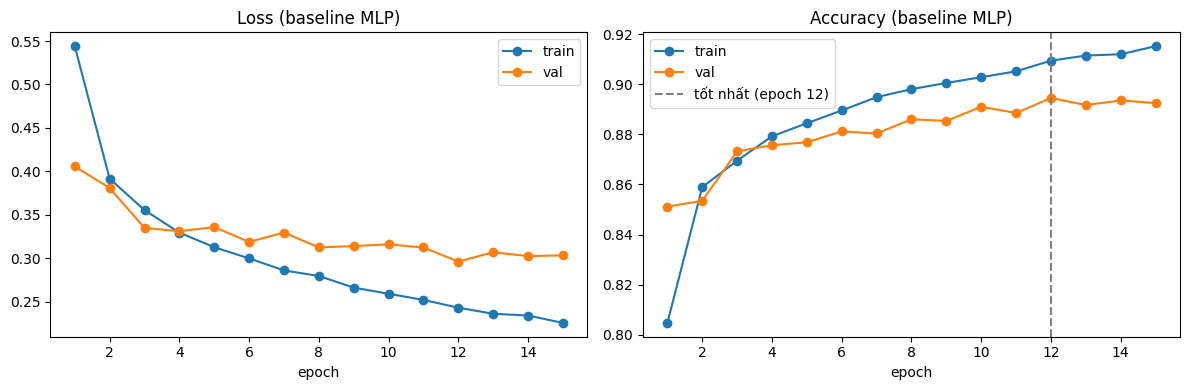

In [19]:
set_seed()
train_loader, val_loader, test_loader = make_loaders(batch_size=128)   # thay các loader ở Phần 1 bằng bản đã cache (kết quả tương đương)

baseline_model = MLP(hidden_sizes=(256, 128), dropout=0.2).to(device)
t0 = time.time()
baseline_hist, baseline_val_acc = fit(baseline_model, train_loader, val_loader,
                                      lr=1e-3, epochs=15, optimizer_name="adam")
print(f"\nBest val acc: {baseline_val_acc:.4f} | Thời gian: {time.time() - t0:.0f}s")
plot_history(baseline_hist, "(baseline MLP)")

**Cách đọc biểu đồ (để trả lời cô):**
- Train loss giảm mà val loss **bắt đầu tăng** → mô hình đang **overfitting**.
- Cả hai đường loss đều cao và gần nhau → **underfitting** (mô hình quá đơn giản hoặc học chưa đủ).
- Khoảng cách giữa train acc và val acc (cột `gap` ở bảng thí nghiệm) là thước đo overfitting đơn giản nhất.

## 7. Thử nghiệm hyperparameter

Đề yêu cầu *"Experiment with network/hyperparameters"*. Nguyên tắc: **mỗi thí nghiệm chỉ đổi MỘT yếu tố so với baseline** để biết yếu tố nào gây ra thay đổi. Mô hình được chọn dựa trên **validation accuracy**; tập **test không được dùng để chọn** (tránh data leakage, chỉ chạm tới ở mục 8).

| Nhóm | Giá trị thử |
|---|---|
| Learning rate | 1e-4, **1e-3 (baseline)**, 1e-2 |
| Batch size | 64, **128**, 256 |
| Kiến trúc | (64,), **(256,128)**, (512,256,128) |
| Optimizer | **Adam**, SGD (momentum 0.9, lr 1e-2), RMSprop |
| Regularization | Dropout 0 / **0.2** / 0.5, weight decay 1e-4 (L2) |

In [20]:
BASE = dict(hidden_sizes=(256, 128), dropout=0.2, lr=1e-3,
            optimizer_name="adam", batch_size=128, weight_decay=0.0, epochs=10)

EXPERIMENTS = {
    "baseline":              {},
    "lr=1e-2":               {"lr": 1e-2},
    "lr=1e-4":               {"lr": 1e-4},
    "batch=64":              {"batch_size": 64},
    "batch=256":             {"batch_size": 256},
    "hidden=(64,)":          {"hidden_sizes": (64,)},
    "hidden=(512,256,128)":  {"hidden_sizes": (512, 256, 128)},
    "SGD (lr=1e-2)":         {"optimizer_name": "sgd", "lr": 1e-2},
    "RMSprop":               {"optimizer_name": "rmsprop"},
    "dropout=0":             {"dropout": 0.0},
    "dropout=0.5":           {"dropout": 0.5},
    "weight_decay=1e-4":     {"weight_decay": 1e-4},
}

GROUPS = {
    "Learning rate":  ["lr=1e-4", "baseline", "lr=1e-2"],
    "Batch size":     ["batch=64", "baseline", "batch=256"],
    "Kiến trúc":      ["hidden=(64,)", "baseline", "hidden=(512,256,128)"],
    "Optimizer":      ["baseline", "SGD (lr=1e-2)", "RMSprop"],
    "Regularization": ["dropout=0", "baseline", "dropout=0.5", "weight_decay=1e-4"],
}

def run_experiment(name, **overrides):
    cfg = {**BASE, **overrides}
    set_seed()
    tr, va, _ = make_loaders(cfg["batch_size"])
    model = MLP(hidden_sizes=cfg["hidden_sizes"], dropout=cfg["dropout"]).to(device)
    t0 = time.time()
    hist, _ = fit(model, tr, va, lr=cfg["lr"], epochs=cfg["epochs"],
                  optimizer_name=cfg["optimizer_name"], weight_decay=cfg["weight_decay"], verbose=False)
    b = int(np.argmax(hist["val_acc"]))
    row = {
        "experiment": name, "hidden": str(cfg["hidden_sizes"]), "dropout": cfg["dropout"],
        "lr": cfg["lr"], "optimizer": cfg["optimizer_name"], "batch": cfg["batch_size"],
        "weight_decay": cfg["weight_decay"], "params": count_params(model),
        "epochs_run": len(hist["val_acc"]), "best_epoch": b + 1,
        "train_acc": hist["train_acc"][b], "val_acc": hist["val_acc"][b],
        "gap": hist["train_acc"][b] - hist["val_acc"][b], "time_s": time.time() - t0,
    }
    state = {k: v.cpu() for k, v in model.state_dict().items()}
    return row, hist, state, cfg

In [21]:
rows, histories, states, cfgs = [], {}, {}, {}
for name, overrides in EXPERIMENTS.items():
    print(f"▶ {name:24s}", end=" ")
    row, hist, state, cfg = run_experiment(name, **overrides)
    rows.append(row); histories[name] = hist; states[name] = state; cfgs[name] = cfg
    print(f"val_acc={row['val_acc']:.4f} | gap={row['gap']:+.4f} | {row['epochs_run']} epochs | {row['time_s']:.0f}s")

df_results = pd.DataFrame(rows).sort_values("val_acc", ascending=False).reset_index(drop=True)
df_results.round(4)

▶ baseline                 val_acc=0.8910 | gap=+0.0118 | 10 epochs | 17s
▶ lr=1e-2                  val_acc=0.8580 | gap=-0.0168 | 10 epochs | 16s
▶ lr=1e-4                  val_acc=0.8728 | gap=+0.0057 | 10 epochs | 20s
▶ batch=64                 val_acc=0.8890 | gap=+0.0117 | 10 epochs | 21s
▶ batch=256                val_acc=0.8902 | gap=+0.0133 | 10 epochs | 13s
▶ hidden=(64,)             val_acc=0.8805 | gap=+0.0067 | 10 epochs | 11s
▶ hidden=(512,256,128)     val_acc=0.8923 | gap=+0.0122 | 10 epochs | 32s
▶ SGD (lr=1e-2)            val_acc=0.8880 | gap=+0.0090 | 10 epochs | 17s
▶ RMSprop                  val_acc=0.8902 | gap=+0.0113 | 10 epochs | 18s
▶ dropout=0                val_acc=0.8932 | gap=+0.0268 | 10 epochs | 15s
▶ dropout=0.5              val_acc=0.8782 | gap=-0.0136 | 10 epochs | 13s
▶ weight_decay=1e-4        val_acc=0.8877 | gap=+0.0129 | 10 epochs | 22s


,experiment,hidden,dropout,lr,optimizer,batch,weight_decay,params,epochs_run,best_epoch,train_acc,val_acc,gap,time_s
0,dropout=0,"(256, 128)",0.0,0.0010,adam,128,0.0000,235146,10,9,0.9199,0.8932,0.0268,14.8513
1,"hidden=(512,256,128)","(512, 256, 128)",0.2,0.0010,adam,128,0.0000,567434,10,10,0.9045,0.8923,0.0122,31.9082
2,baseline,"(256, 128)",0.2,0.0010,adam,128,0.0000,235146,10,10,0.9028,0.8910,0.0118,16.8288
3,RMSprop,"(256, 128)",0.2,0.0010,rmsprop,128,0.0000,235146,10,10,0.9015,0.8902,0.0113,17.5165
4,batch=256,"(256, 128)",0.2,0.0010,adam,256,0.0000,235146,10,10,0.9035,0.8902,0.0133,13.4594
5,batch=64,"(256, 128)",0.2,0.0010,adam,64,0.0000,235146,10,10,0.9007,0.8890,0.0117,20.7177
6,SGD (lr=1e-2),"(256, 128)",0.2,0.0100,sgd,128,0.0000,235146,10,10,0.8970,0.8880,0.0090,16.5304
7,weight_decay=1e-4,"(256, 128)",0.2,0.0010,adam,128,0.0001,235146,10,10,0.9006,0.8877,0.0129,22.0822
8,"hidden=(64,)","(64,)",0.2,0.0010,adam,128,0.0000,50890,10,10,0.8872,0.8805,0.0067,10.6858
9,dropout=0.5,"(256, 128)",0.5,0.0010,adam,128,0.0000,235146,10,7,0.8646,0.8782,-0.0136,13.4826


### 7.1 Trực quan kết quả thí nghiệm

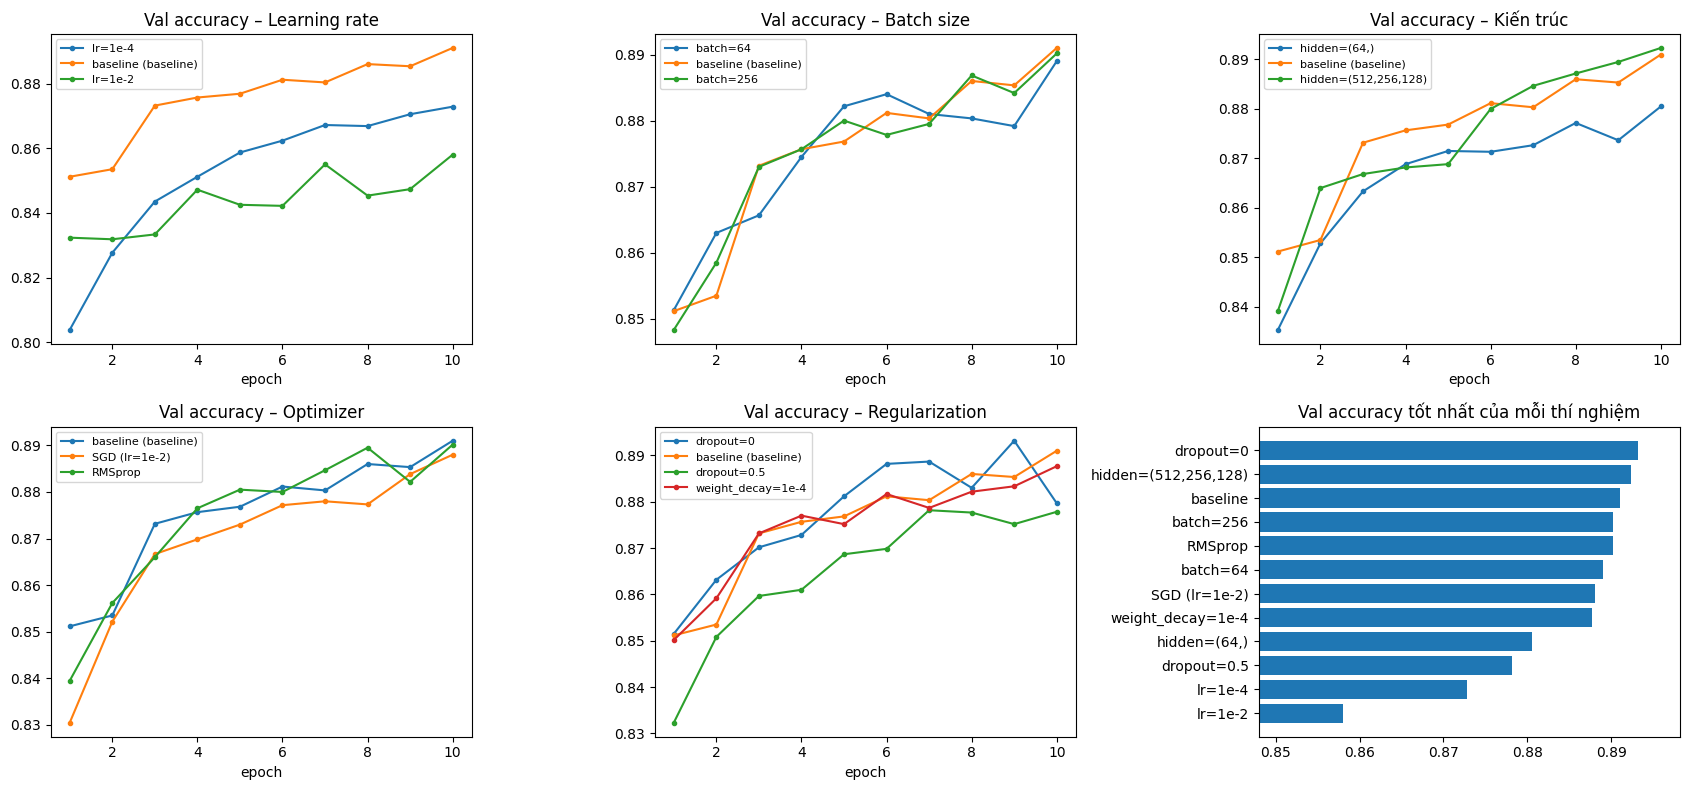

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
axes = axes.ravel()

for ax, (group, names) in zip(axes, GROUPS.items()):
    for n in names:
        label = n + (" (baseline)" if n == "baseline" else "")
        ax.plot(range(1, len(histories[n]["val_acc"]) + 1), histories[n]["val_acc"], marker="o", ms=3, label=label)
    ax.set_title(f"Val accuracy – {group}"); ax.set_xlabel("epoch"); ax.legend(fontsize=8)

ax = axes[-1]
order = df_results.sort_values("val_acc")
ax.barh(order["experiment"], order["val_acc"])
ax.set_xlim(order["val_acc"].min() - 0.01, order["val_acc"].max() + 0.005)
ax.set_title("Val accuracy tốt nhất của mỗi thí nghiệm")
plt.tight_layout(); plt.show()

### 7.2 Chọn mô hình tốt nhất (theo validation)

In [23]:
best_name = df_results.loc[0, "experiment"]
best_cfg  = cfgs[best_name]
print("Cấu hình tốt nhất theo val acc:", best_name)
print({k: best_cfg[k] for k in ("hidden_sizes", "dropout", "lr", "optimizer_name", "batch_size", "weight_decay")})
print(f"Val acc = {df_results.loc[0, 'val_acc']:.4f}")

final_model = MLP(hidden_sizes=best_cfg["hidden_sizes"], dropout=best_cfg["dropout"]).to(device)
final_model.load_state_dict(states[best_name])

Cấu hình tốt nhất theo val acc: dropout=0
{'hidden_sizes': (256, 128), 'dropout': 0.0, 'lr': 0.001, 'optimizer_name': 'adam', 'batch_size': 128, 'weight_decay': 0.0}
Val acc = 0.8932


<All keys matched successfully>

## 8. Đánh giá cuối cùng trên tập Test

Đây là lần **duy nhất** mô hình đã chọn chạm vào tập test (10.000 ảnh chưa từng dùng khi huấn luyện hay chọn tham số). Các metric theo slide 14 Chương 2: accuracy, precision, recall, F1, confusion matrix.

In [24]:
@torch.no_grad()
def predict(model, loader):
    model.eval()
    ys, ps = [], []
    for x, y in loader:
        out = model(x.to(device))
        ps.append(out.argmax(1).cpu()); ys.append(y)
    return torch.cat(ys).numpy(), torch.cat(ps).numpy()

y_true, y_pred = predict(final_model, test_loader)
test_acc = (y_true == y_pred).mean()
print(f"Test accuracy: {test_acc:.4f}  ({(y_true == y_pred).sum()}/{len(y_true)} ảnh đúng)\n")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

Test accuracy: 0.8867  (8867/10000 ảnh đúng)

              precision    recall  f1-score   support

 T-shirt/top     0.7984    0.8830    0.8386      1000
     Trouser     0.9868    0.9740    0.9804      1000
    Pullover     0.7758    0.8410    0.8071      1000
       Dress     0.9079    0.8580    0.8823      1000
        Coat     0.8189    0.8140    0.8164      1000
      Sandal     0.9746    0.9580    0.9662      1000
       Shirt     0.7449    0.6570    0.6982      1000
     Sneaker     0.9414    0.9480    0.9447      1000
         Bag     0.9729    0.9690    0.9709      1000
  Ankle boot     0.9498    0.9650    0.9573      1000

    accuracy                         0.8867     10000
   macro avg     0.8871    0.8867    0.8862     10000
weighted avg     0.8871    0.8867    0.8862     10000



### 8.1 Confusion matrix

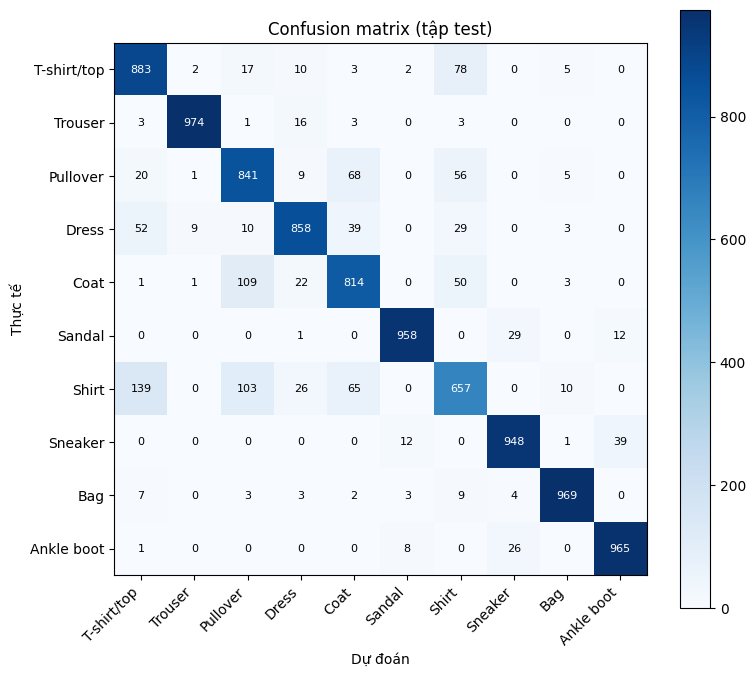

5 kiểu nhầm lẫn nhiều nhất:
  Shirt bị nhận nhầm thành T-shirt/top: 139 ảnh
  Coat bị nhận nhầm thành Pullover: 109 ảnh
  Shirt bị nhận nhầm thành Pullover: 103 ảnh
  T-shirt/top bị nhận nhầm thành Shirt: 78 ảnh
  Pullover bị nhận nhầm thành Coat: 68 ảnh

Đối chiếu với mục 2.6: các lớp có ảnh trung bình gần nhau có phải là các lớp bị nhầm nhiều không?


In [25]:
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10)); ax.set_xticklabels(CLASS_NAMES, rotation=45, ha="right")
ax.set_yticks(range(10)); ax.set_yticklabels(CLASS_NAMES)
ax.set_xlabel("Dự đoán"); ax.set_ylabel("Thực tế"); ax.set_title("Confusion matrix (tập test)")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8,
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im); plt.tight_layout(); plt.show()

off_diag = [(cm[i, j], CLASS_NAMES[i], CLASS_NAMES[j]) for i in range(10) for j in range(10) if i != j]
print("5 kiểu nhầm lẫn nhiều nhất:")
for c, a, b in sorted(off_diag, reverse=True)[:5]:
    print(f"  {a} bị nhận nhầm thành {b}: {c} ảnh")
print("\nĐối chiếu với mục 2.6: các lớp có ảnh trung bình gần nhau có phải là các lớp bị nhầm nhiều không?")

### 8.2 Hiển thị ảnh dự đoán so với thực tế

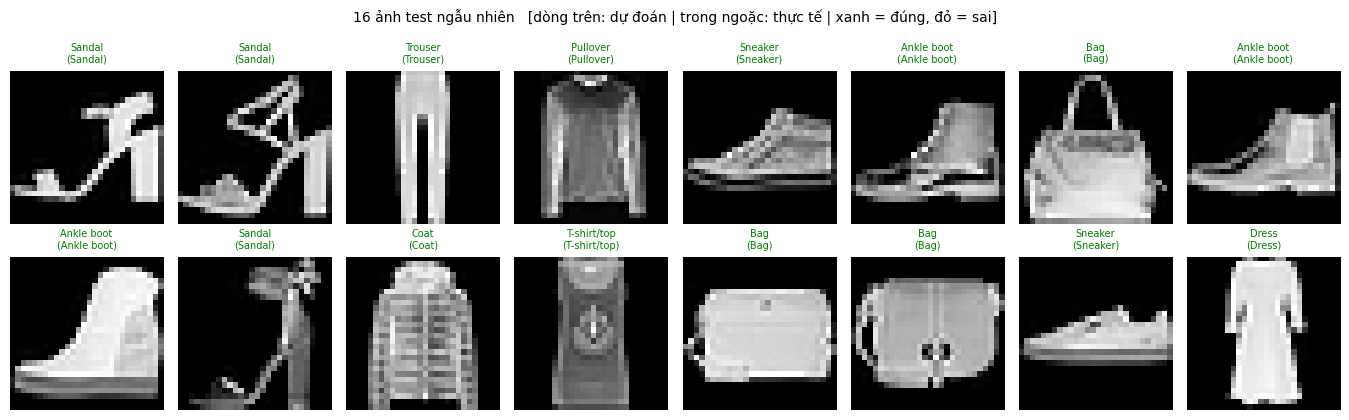

Số ảnh dự đoán sai: 1133/10000


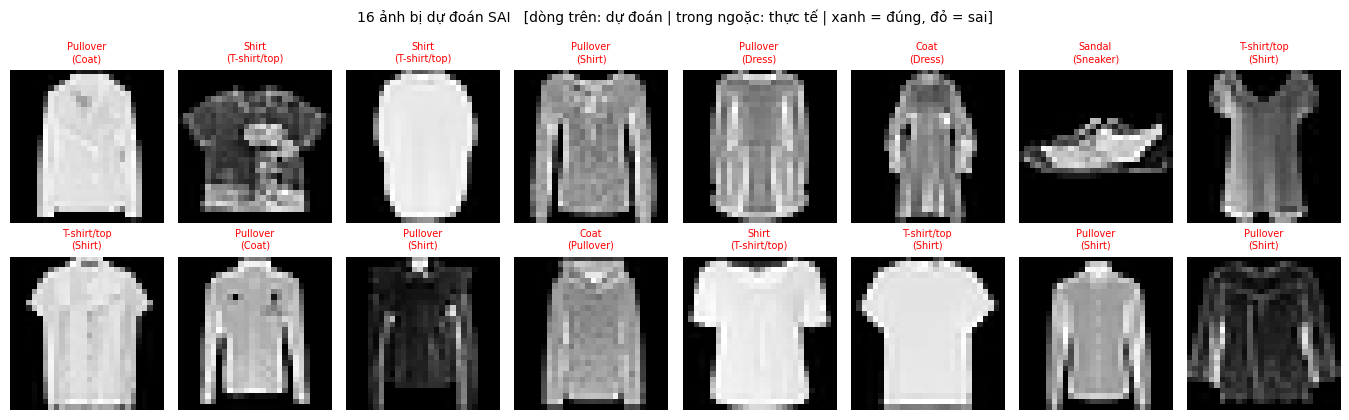

In [26]:
def show_samples(X, y_true, y_pred, indices, title):
    cols = 8
    rows_n = int(np.ceil(len(indices) / cols))
    fig, axes = plt.subplots(rows_n, cols, figsize=(cols * 1.7, rows_n * 2.2))
    axes = np.atleast_2d(axes)
    for ax in axes.ravel():
        ax.axis("off")
    for ax, i in zip(axes.ravel(), indices):
        img = X[i].squeeze().numpy() * STD + MEAN          # đảo chuẩn hóa để hiển thị
        ax.imshow(img, cmap="gray", vmin=0, vmax=1)
        ok = y_true[i] == y_pred[i]
        ax.set_title(f"{CLASS_NAMES[y_pred[i]]}\n({CLASS_NAMES[y_true[i]]})", fontsize=7,
                     color="green" if ok else "red")
    fig.suptitle(title + "   [dòng trên: dự đoán | trong ngoặc: thực tế | xanh = đúng, đỏ = sai]", fontsize=10)
    plt.tight_layout(); plt.show()

rng = np.random.default_rng(SEED)
show_samples(X_test_t, y_true, y_pred, rng.choice(len(y_true), 16, replace=False), "16 ảnh test ngẫu nhiên")

wrong = np.where(y_true != y_pred)[0]
print(f"Số ảnh dự đoán sai: {len(wrong)}/{len(y_true)}")
show_samples(X_test_t, y_true, y_pred, rng.choice(wrong, 16, replace=False), "16 ảnh bị dự đoán SAI")

## 9. (Bonus) So sánh với CNN

Slide 16 Chương 2 nói MLP không phù hợp ảnh vì mất thông tin không gian. Ta kiểm chứng bằng một CNN nhỏ (2 khối Conv–BatchNorm–ReLU–MaxPool), huấn luyện bằng **cùng hàm `fit`** và cùng dữ liệu.

Số tham số CNN: 421,834 | MLP tốt nhất: 235,146
Epoch 01/8 | train loss 0.4593 acc 0.8376 | val loss 0.3028 acc 0.8865 | 15.4s
Epoch 02/8 | train loss 0.3072 acc 0.8891 | val loss 0.2737 acc 0.9002 | 15.3s
Epoch 03/8 | train loss 0.2711 acc 0.9004 | val loss 0.2594 acc 0.9050 | 15.4s
Epoch 04/8 | train loss 0.2444 acc 0.9109 | val loss 0.2376 acc 0.9168 | 15.9s
Epoch 05/8 | train loss 0.2246 acc 0.9164 | val loss 0.2265 acc 0.9173 | 15.5s
Epoch 06/8 | train loss 0.2050 acc 0.9239 | val loss 0.2412 acc 0.9122 | 15.2s
Epoch 07/8 | train loss 0.1910 acc 0.9285 | val loss 0.2251 acc 0.9158 | 15.3s
Epoch 08/8 | train loss 0.1766 acc 0.9339 | val loss 0.2215 acc 0.9215 | 15.2s

CNN best val acc: 0.9215 | Thời gian: 123s


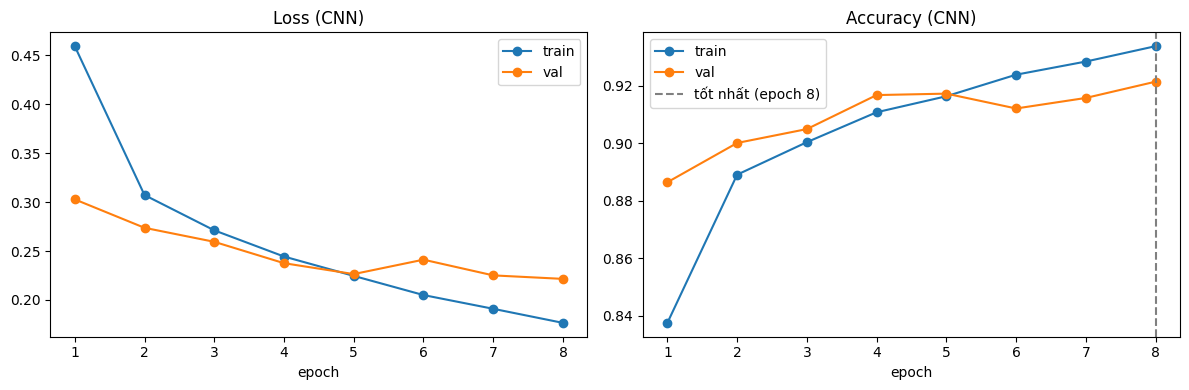

,mô hình,tham số,val acc,test acc
0,MLP (tốt nhất),235146,0.8932,0.8867
1,CNN nhỏ,421834,0.9215,0.9159


In [27]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes=10, dropout=0.3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),    # 28x28 -> 14x14
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),   # 14x14 -> 7x7
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Linear(64 * 7 * 7, 128), nn.ReLU(), nn.Dropout(dropout), nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

set_seed()
cnn = SmallCNN().to(device)
print("Số tham số CNN:", f"{count_params(cnn):,}", "| MLP tốt nhất:", f"{count_params(final_model):,}")

t0 = time.time()
cnn_hist, cnn_val_acc = fit(cnn, train_loader, val_loader, lr=1e-3, epochs=8, optimizer_name="adam")
print(f"\nCNN best val acc: {cnn_val_acc:.4f} | Thời gian: {time.time() - t0:.0f}s")
plot_history(cnn_hist, "(CNN)")

y_true_c, y_pred_c = predict(cnn, test_loader)
compare = pd.DataFrame({
    "mô hình":  ["MLP (tốt nhất)", "CNN nhỏ"],
    "tham số":  [count_params(final_model), count_params(cnn)],
    "val acc":  [df_results.loc[0, "val_acc"], cnn_val_acc],
    "test acc": [(y_true == y_pred).mean(), (y_true_c == y_pred_c).mean()],
})
compare.round(4)

## 10. Lưu và nạp lại mô hình

Lưu `state_dict` (chỉ trọng số, cách khuyến nghị ở slide 12 Chương 3) kèm cấu hình, `MEAN`, `STD` và tên lớp để sau này có thể suy luận độc lập.

Đã lưu: best_mlp_fashionmnist.pth
Test acc sau khi nạp lại: 0.8867 | giống mô hình gốc: True


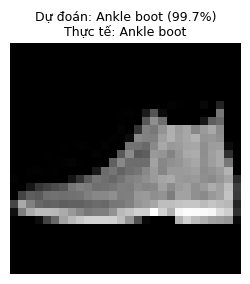

In [28]:
CKPT_PATH = "best_mlp_fashionmnist.pth"
torch.save({
    "state_dict": final_model.state_dict(),
    "config": {"hidden_sizes": list(best_cfg["hidden_sizes"]), "dropout": best_cfg["dropout"]},
    "mean": MEAN, "std": STD, "classes": CLASS_NAMES,
}, CKPT_PATH)
print("Đã lưu:", CKPT_PATH)

# --- Nạp lại vào một mô hình mới ---
ckpt = torch.load(CKPT_PATH, map_location=device)
loaded = MLP(hidden_sizes=tuple(ckpt["config"]["hidden_sizes"]), dropout=ckpt["config"]["dropout"]).to(device)
loaded.load_state_dict(ckpt["state_dict"])
loaded.eval()                      # chỉ suy luận -> eval()

y_true_l, y_pred_l = predict(loaded, test_loader)
print("Test acc sau khi nạp lại:", (y_true_l == y_pred_l).mean(), "| giống mô hình gốc:", bool((y_pred_l == y_pred).all()))

# --- Suy luận trên MỘT ảnh thô (uint8 0-255) như khi triển khai thực tế ---
i = 0
img_raw = X_test_raw[i]
x = torch.from_numpy(img_raw.astype(np.float32) / 255.0)
x = ((x - ckpt["mean"]) / ckpt["std"]).unsqueeze(0).unsqueeze(0).to(device)   # (1, 1, 28, 28)
with torch.no_grad():
    probs = torch.softmax(loaded(x), dim=1)[0].cpu().numpy()

plt.figure(figsize=(3, 3)); plt.imshow(img_raw, cmap="gray"); plt.axis("off")
plt.title(f"Dự đoán: {ckpt['classes'][probs.argmax()]} ({probs.max():.1%})\nThực tế: {ckpt['classes'][y_test[i]]}", fontsize=9)
plt.show()

## 11. Tổng kết và checklist nộp bài


|---|---|

| Load FashionMNIST | Mục 1 |

| Apply transforms | Mục 3.3 (và 5.1) |

| Build a neural network | Mục 5 |

| Training loop (forward, loss, backward, optimize) | Mục 6 |

| Evaluate model accuracy | Mục 7.2, 8 |

| Save and load the model | Mục 10 |

| Experiment with network / hyperparameters | Mục 7 |

| Visualize loss | Mục 6.1, 9 (hàm `plot_history`) |

| Display predicted vs actual images | Mục 8.2 |



